In [1]:
import pandas as pd

In [2]:
df= pd.read_csv("C:/Ruquayya Banu/Data Science/Datasets/diamonds.csv")

In [3]:
df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [4]:
# case study - prediction of price

In [5]:
df.columns

Index(['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y',
       'z'],
      dtype='object')

In [6]:
df.shape

(53940, 10)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


In [8]:
df.isnull().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [9]:
# basic statistical understanding

In [10]:
df.describe(include= "all")

,carat,cut,color,clarity,depth,table,price,x,y,z
count,53940.000000,53940,53940,53940,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
unique,NaN,5,7,8,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Ideal,G,SI1,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,21551,11292,13065,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.797940,NaN,NaN,NaN,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,NaN,NaN,NaN,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,NaN,NaN,NaN,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,NaN,NaN,NaN,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,NaN,NaN,NaN,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,NaN,NaN,NaN,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000


In [11]:
df["cut"].value_counts()

cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64

In [12]:
df["color"].value_counts()

color
G    11292
E     9797
F     9542
H     8304
D     6775
I     5422
J     2808
Name: count, dtype: int64

In [13]:
df["clarity"].value_counts()

clarity
SI1     13065
VS2     12258
SI2      9194
VS1      8171
VVS2     5066
VVS1     3655
IF       1790
I1        741
Name: count, dtype: int64

In [14]:
df.rename(columns={'x': 'length','y':'width','z':'depth','depth':"depth_percentage"}, inplace=True)

In [15]:
df

,carat,cut,color,clarity,depth_percentage,table,price,length,width,depth
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [16]:
df.loc[(df["length"]==0) | (df["width"]==0) | (df["depth"]==0)]

,carat,cut,color,clarity,depth_percentage,table,price,length,width,depth
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.00,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
13601,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0
15951,1.14,Fair,G,VS1,57.5,67.0,6381,0.00,0.00,0.0
24394,2.18,Premium,H,SI2,59.4,61.0,12631,8.49,8.45,0.0


In [17]:
len(df.loc[(df["length"]==0) | (df["width"]==0) | (df["depth"]==0)])

20

In [18]:
# deleting all the zero's - which ever row have contain zero value remove row 

In [19]:
df= df.drop(index =df.loc[(df["length"]==0) | (df["width"]==0) | (df["depth"]==0)].index )

In [20]:
df

,carat,cut,color,clarity,depth_percentage,table,price,length,width,depth
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [21]:
# pre processing :- 
# split the data
# encoding for categorical columns:- 
#      ordinal encoding- label encoding and ordinal encoding
#      norminal encoding- one hot coding and get_dummies
# scaling for numerical columns:-
#      standardization (z transformation)

In [22]:
#seperating input and target feature(column)
x = df[["carat","cut","color","clarity","depth_percentage","table","length","width","depth"]] #input feature
y = df[["price"]] #target feature

In [23]:
#spliting data into train and test
#Note:- Do not change the below line and variable name position for any dataset during splitting
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size= 0.7,random_state = 20)

In [24]:
# sepearting categorical and numerical column

In [25]:
x_train.dtypes

carat               float64
cut                  object
color                object
clarity              object
depth_percentage    float64
table               float64
length              float64
width               float64
depth               float64
dtype: object

In [26]:
# categorical features are
x_train_cat = x_train.select_dtypes(include = ["object"])
x_train_cat

,cut,color,clarity
29880,Very Good,D,VS2
40542,Premium,E,IF
40178,Premium,E,VVS1
30355,Very Good,D,SI1
45682,Ideal,F,VS1
...,...,...,...
23461,Premium,H,SI1
23784,Very Good,D,SI2
37152,Ideal,D,VS2
27111,Premium,H,SI1


In [27]:
# numerical features are
x_train_num = x_train.select_dtypes(include = ["int64","float64"])
x_train_num

,carat,depth_percentage,table,length,width,depth
29880,0.30,62.8,59.0,4.26,4.28,2.68
40542,0.35,59.0,61.0,4.64,4.62,2.73
40178,0.38,60.6,59.0,4.65,4.62,2.81
30355,0.33,63.1,55.0,4.40,4.38,2.77
45682,0.50,61.6,57.0,5.07,5.09,3.13
...,...,...,...,...,...,...
23461,1.62,62.2,58.0,7.50,7.46,4.65
23784,1.71,63.5,56.0,7.58,7.51,4.79
37152,0.32,62.2,56.0,4.39,4.36,2.72
27111,2.02,62.1,61.0,8.06,7.99,4.98


In [28]:
#scaling the numerical features - for train data

In [29]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_num_rescale = pd.DataFrame(scaler.fit_transform(x_train_num),columns = x_train_num.columns,index = x_train_num.index)
x_train_num_rescale.head()

,carat,depth_percentage,table,length,width,depth
29880,-1.048904,0.738706,0.697742,-1.314132,-1.298439,-1.215525
40542,-0.943263,-1.927502,1.596306,-0.974178,-0.994338,-1.144728
40178,-0.879878,-0.804888,0.697742,-0.965232,-0.994338,-1.031454
30355,-0.985519,0.949196,-1.099387,-1.188886,-1.208997,-1.088091
45682,-0.626339,-0.103254,-0.200822,-0.589493,-0.573962,-0.578357


In [30]:
#seperater the nominal and ordinal columns from x train data
x_train_cat_le = x_train_cat["cut"]
x_train_cat_le.value_counts()

cut
Ideal        15130
Premium       9644
Very Good     8425
Good          3430
Fair          1115
Name: count, dtype: int64

In [31]:
#encoding technique on cut column/feature
cut_encoder = {"Fair":1,"Good":2,"Very Good":3,"Ideal":4,"Premium":5}
x_train_cat_le = x_train_cat["cut"].apply(lambda x:cut_encoder[x])
x_train_cat_le

29880    3
40542    5
40178    5
30355    3
45682    4
        ..
23461    5
23784    3
37152    4
27111    5
48500    3
Name: cut, Length: 37744, dtype: int64

In [32]:
#seperate  nominal type of data 
x_train_cat_onehot = x_train_cat[["color","clarity"]]
x_train_cat_onehot.head()

,color,clarity
29880,D,VS2
40542,E,IF
40178,E,VVS1
30355,D,SI1
45682,F,VS1


In [33]:
#one hot encoding technique on color and clarity column 
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(drop = "first",sparse_output = False) # drop one coloum from each category which got created 
encoded = encoder.fit_transform(x_train_cat_onehot[["color","clarity"]])
encoded.shape #for every new value(E,F,G,H....) it create a new column


(37744, 13)

In [34]:
#encoded = pd.DataFrame(encoded, columns = encoder.get_feature_names_out(["color","clarity"]),index = x_train_cat_onehot.index)
#   ******** or  *****
encoded = encoder.fit_transform(x_train_cat_onehot)

encoded = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(["color", "clarity"]),
    index=x_train_cat_onehot.index
)                    
encoded

,color_E,color_F,color_G,color_H,color_I,color_J,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
29880,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
40542,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
40178,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
30355,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
45682,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
23461,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
23784,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
37152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
27111,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [35]:
df["cut"].isnull().sum()

np.int64(0)

In [36]:
# concatenating label encoding feature with one hot encoded
x_train_transformed =pd.concat([encoded,x_train_cat_le],axis = 1)
x_train_transformed.head()

,color_E,color_F,color_G,color_H,color_I,color_J,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2,cut
29880,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,3
40542,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,5
40178,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,5
30355,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3
45682,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,4


In [37]:
# *********above code is for trained data and it is ready for ML model **************8

In [38]:
# scaling the test data - from splitting data

In [39]:
x_test

,carat,cut,color,clarity,depth_percentage,table,length,width,depth
51907,0.70,Good,E,SI2,63.7,55.0,5.63,5.58,3.57
38439,0.35,Very Good,F,IF,62.0,54.0,4.55,4.58,2.83
17594,1.00,Good,E,VVS1,64.1,62.0,6.29,6.26,4.02
30176,0.29,Ideal,G,IF,61.3,56.0,4.26,4.29,2.62
44681,0.50,Premium,D,SI1,62.3,58.0,5.08,5.07,3.16
...,...,...,...,...,...,...,...,...,...
11619,1.01,Ideal,G,SI1,60.6,59.0,6.45,6.49,3.92
37428,0.34,Premium,D,VVS2,60.1,58.0,4.53,4.55,2.73
18688,1.50,Premium,F,SI2,58.5,60.0,7.52,7.48,4.39
42894,0.51,Premium,H,VS2,58.5,61.0,5.26,5.23,3.07


In [40]:
#seperate the numerical columns
x_test_num = x_test.select_dtypes(include = ["int64","float64"])

x_test_num_rescale = pd.DataFrame(scaler.transform(x_test_num),columns = x_test_num.columns,index = x_test_num.index)
x_test_num_rescale.head()

,carat,depth_percentage,table,length,width,depth
51907,-0.203774,1.370177,-1.099387,-0.088508,-0.135699,0.044651
38439,-0.943263,0.177399,-1.548669,-1.054694,-1.030114,-1.003136
17594,0.430073,1.650830,2.045589,0.501938,0.472504,0.681818
30176,-1.070032,-0.313744,-0.650105,-1.314132,-1.289495,-1.300480
44681,-0.626339,0.387889,0.248460,-0.580547,-0.591851,-0.535880


In [41]:
#seperate the categorical columns
x_test_cat = x_test.select_dtypes(include = ["object"])
# label encoding for test data
cut_encoder = {"Fair":1,"Good":2,"Very Good":3,"Ideal":4,"Premium":5}
x_test_cat_le = x_test_cat["cut"].apply(lambda x:cut_encoder[x])
x_test_cat_le.isnull().sum()

np.int64(0)

In [42]:
#one hot encoding for test data
x_test_cat_onehot = x_test_cat[["color","clarity"]]
encoded = encoder.transform(x_test_cat_onehot[["color","clarity"]])
encoded = pd.DataFrame(encoded,columns=encoder.get_feature_names_out(["color", "clarity"]),index=x_test_cat_onehot.index) 
encoded

,color_E,color_F,color_G,color_H,color_I,color_J,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
51907,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
38439,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
17594,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
30176,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
44681,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11619,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
37428,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
18688,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
42894,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [43]:
# concatenating label encoding feature with one hot encoded - for test data
x_test_transformed =pd.concat([encoded,x_test_cat_le],axis = 1)
x_test_transformed.head()

,color_E,color_F,color_G,color_H,color_I,color_J,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2,cut
51907,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2
38439,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,3
17594,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2
30176,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,4
44681,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,5


In [44]:
#  ***********above test data is ready for ML models ***********

In [45]:
 # KNN Regression

In [46]:
from sklearn.neighbors import KNeighborsRegressor
regressor = KNeighborsRegressor()
regressor.fit(x_train_transformed,y_train) #teaching the modal


KNeighborsRegressor()

In [47]:
#validating the model(KNN)
y_test_pred = regressor.predict(x_test_transformed)
y_test_pred,y_test # compare the predction and actually value
#after looking the value some values are up and down, which means our model is working fine 

(array([[9226.8],
        [2711.8],
        [2740.6],
        ...,
        [3522. ],
        [6079.2],
        [8559.6]]),
        price
 51907   2435
 38439   1027
 17594   7084
 30176    721
 44681   1610
 ...      ...
 11619   5049
 37428    984
 18688   7644
 42894   1359
 40299   1125
 
 [16176 rows x 1 columns])

<Axes: ylabel='Count'>

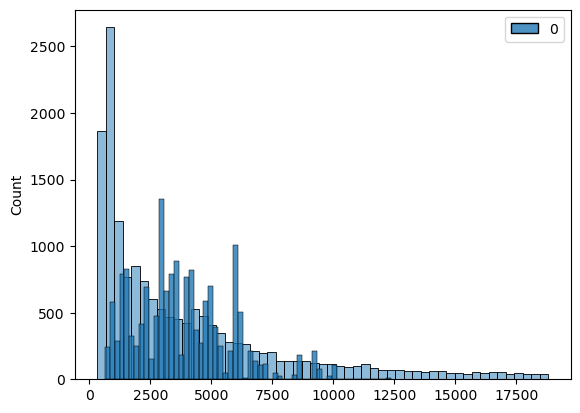

In [48]:
# check predicted and actually value
import seaborn as sns
sns.histplot(y_test, color="blue", alpha=0.5)
sns.histplot(y_test_pred,color = "red", alpha =0.8)

In [49]:
# judging the performance of the regression model - checking with error metric
from sklearn.metrics import mean_absolute_error , mean_squared_error
print("Mean absolute error",mean_absolute_error(y_test, y_test_pred))

Mean absolute error 2962.209248269041


In [50]:
print("Mean squared error",mean_squared_error(y_test, y_test_pred))

Mean squared error 16943598.080642927


In [51]:
import numpy as np
print("Root mean square",np.sqrt(mean_squared_error(y_test, y_test_pred)))

Root mean square 4116.260205653055


In [52]:
# conclusion - KNN regressor
# while evaluating the KNN regressor, the concept of "percentage accuracy" is not directly applicable in the same way as it is for classiffication type of model
#for regression task the goal is to achive or to predict the continous numerical value, not any category
# therefore matrices like accuracy which measure the proportion of correct prediction are not suitable
# insted we judge the performance with the error metrics

#MAE(Mean absolute error): this measure the average absolute difference between prediction and actual value.
#MSE(Mean squared error): the average of the square distance between predicted and the avarage value. I t penalize larger error more heavily
#RMSE(Root mean squared error): this is the square root of MSE and often preferred because it is in the same unit as the target variable.

In [53]:
# we are calculating the root mean squared error 
# RMSE represent the average prediction error - typically the distance between your model prediction price and the actual price
# RMSE = 810.05 my model price prediction are off by 810 units.(e.g 810rs,$820, etc)

In [59]:
# how to tell if it is a good or bad performance 
# 810/3930 = 0.26
# 0.26 ~ 20.6% error
# accuracy will be 80% - it is a good model or performance 

In [55]:
df["price"]

0         326
1         326
2         327
3         334
4         335
         ... 
53935    2757
53936    2757
53937    2757
53938    2757
53939    2757
Name: price, Length: 53920, dtype: int64

In [57]:
df["price"].describe() 
#lets consider 3930 as the average price which represent the entire price column

count    53920.000000
mean      3930.993231
std       3987.280446
min        326.000000
25%        949.000000
50%       2401.000000
75%       5323.250000
max      18823.000000
Name: price, dtype: float64

In [58]:
810/3930

0.20610687022900764